# multiPPIseq DMS pipeline walkthrough

This notebook runs the full multiPPIseq DMS pipeline end-to-end on the bundled
**example data**, calling the pipeline scripts directly (the same commands the
`qsub/` job scripts issue, but run inline here instead of submitted to the
cluster).

Two halves are covered:

1. **Dictionary build** &mdash; `step1` (barcode + variant-oligo extraction) ->
   `bowtie2`/`samtools` (align oligos) -> `step2` (assign variants to reads) ->
   `step3` (collapse to a barcode-to-variant dictionary).
2. **cDNA edit counting** &mdash; `parse step1` (expand dictionary barcodes to
   their edited forms) -> `parse step2` (count edits per variant).

The example features **RAD51C**, one block per library type, restricted to a few
consecutive residues with strong editing signal (see `example_data/README.md`).
Pick the library type in the config cell below.

**Requirements:** run this notebook with a Python kernel that has `pysam`,
`pandas`, `numpy` and `matplotlib` (e.g. the `access` conda env), with `bowtie2`
and `samtools` available. The pipeline scripts are invoked through the kernel's
own interpreter (`sys.executable`); set `PY` / `BOWTIE2` / `SAMTOOLS` in the
config cell if yours live elsewhere.

## Configuration

Locate the repo and tools, choose the library type, and set up a disposable work directory.

In [1]:
import os, sys, shutil, subprocess, tempfile, gzip
from pathlib import Path

# --- locate the repo root (the dir containing script/ and example_data/) ---
def find_repo(start):
    for p in [start, *start.parents]:
        if (p / "script" / "dict_build").is_dir() and (p / "example_data").is_dir():
            return p
    raise RuntimeError("could not find repo root from %s" % start)

REPO = find_repo(Path.cwd())
ED = REPO / "example_data"
REF = REPO / "ref" / "dict_build"
IDX = REF / "bowtie2_index" / "block_ref_seqs_061626"

# --- tools (override here or via env vars if not on PATH) ---
PY       = os.environ.get("PY")       or sys.executable
BOWTIE2  = os.environ.get("BOWTIE2")  or shutil.which("bowtie2")  or "/net/bin/x86_64/bowtie2"
SAMTOOLS = os.environ.get("SAMTOOLS") or shutil.which("samtools") or "samtools"

print("Repo:    ", REPO)
print("Python:  ", PY)
print("bowtie2: ", BOWTIE2)
print("samtools:", SAMTOOLS)

Repo:     /net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central
Python:   /net/apps/conda/miniconda3/envs/access/bin/python
bowtie2:  /net/bin/x86_64/bowtie2
samtools: /net/apps/conda/miniconda3/envs/access/bin/samtools


In [2]:
# --- pick the library type -------------------------------------------------
LIBTYPE = "Dual_NEBuilder"     # "Dual_NEBuilder" or "regular"

CFG = {
    # per-block cutoffs for the messy NEBuilder construct
    "Dual_NEBuilder": dict(block=1, min_support=5, min_acc=0.10, residues=range(109, 114)),
    # global cutoffs for the clean regular construct
    "regular":        dict(block=3, min_support=3, min_acc=0.90, residues=range(232, 237)),
}[LIBTYPE]

BLOCK = CFG["block"]
PREFIX = "RAD51C_DMS_%d" % BLOCK
# R1 linker == cDNA edit template (production config)
TEMPLATE = "TATCATACggccctgcagacatgggtgatcctcatgttggccTGTAGTACC"

DICT_R1 = ED / LIBTYPE / "dict_build" / ("%s_Dictionary_R1.fastq.gz" % PREFIX)
DICT_R2 = ED / LIBTYPE / "dict_build" / ("%s_Dictionary_R2.fastq.gz" % PREFIX)
CDNA_R1 = ED / LIBTYPE / "cdna_edit_count" / "NR-TV_HCT_RAD51C_XRCC3_Rep1__R1.fastq.gz"
EXPECT  = ED / LIBTYPE / "expected_output"

WORK = Path(tempfile.mkdtemp(prefix="ppiseq_%s_" % LIBTYPE))

print("Library type:", LIBTYPE)
print("  block %d, residues %s" % (BLOCK, list(CFG["residues"])))
print("  step3 cutoffs: support >= %d, fidelity >= %.2f" % (CFG["min_support"], CFG["min_acc"]))
print("Work dir:", WORK)

Library type: Dual_NEBuilder
  block 1, residues [109, 110, 111, 112, 113]
  step3 cutoffs: support >= 5, fidelity >= 0.10
Work dir: /tmp/ppiseq_Dual_NEBuilder_spx9i86f


In [3]:
def run(cmd, log_tail=None):
    """Run a command, echo it, and stream its output. Raises on failure."""
    cmd = [str(c) for c in cmd]
    print("$", " ".join(cmd), "\n")
    r = subprocess.run(cmd, capture_output=True, text=True)
    out = (r.stdout or "") + (r.stderr or "")
    if log_tail:
        out = "\n".join(out.splitlines()[-log_tail:])
    print(out)
    r.check_returncode()
    return r

In [4]:
# bowtie2 index is not committed (regenerable); build it once from the reference FASTA.
if not Path(str(IDX) + ".1.bt2").exists():
    run([str(BOWTIE2) + "-build", REF / "block_ref_seqs_061626.fa", IDX], log_tail=3)
else:
    print("bowtie2 index already present:", IDX)

bowtie2 index already present: /net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/ref/dict_build/bowtie2_index/block_ref_seqs_061626


## Part 1 &mdash; Dictionary build

### Step 1: extract the variant barcode and variant oligo

`step1_v2.py` reads each pair: from **R1** it takes the variant barcode (bc1,
upstream of the constant linker); from **R2** it takes the variant oligo (after
the block-specific fixed sequence). It writes a FASTA of oligos whose headers
carry the barcode, ready to align. `--ignore_bc2` is not needed here &mdash; bc2 is
simply left unused downstream.

In [5]:
run([PY, REPO / "script/dict_build/multiPPIseq_DMS_dict_build_step1_v2.py",
     "--r1_fastq", DICT_R1, "--r2_fastq", DICT_R2,
     "--r1_linker", TEMPLATE,
     "--r2_fixed_seq_lib", REF / "r2_fixed_seq_061626.csv",
     "--bc1_min_len", 12, "--bc1_max_len", 15,
     "--bc2_min_len", 2, "--bc2_max_len", 7,
     "--r1_post_bc2", "ACCTTTCGACCT",
     "--out", WORK / ("%s_Dictionary.fasta.gz" % PREFIX)])

$ /net/apps/conda/miniconda3/envs/access/bin/python /net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/script/dict_build/multiPPIseq_DMS_dict_build_step1_v2.py --r1_fastq /net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/example_data/Dual_NEBuilder/dict_build/RAD51C_DMS_1_Dictionary_R1.fastq.gz --r2_fastq /net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/example_data/Dual_NEBuilder/dict_build/RAD51C_DMS_1_Dictionary_R2.fastq.gz --r1_linker TATCATACggccctgcagacatgggtgatcctcatgttggccTGTAGTACC --r2_fixed_seq_lib /net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/ref/dict_build/r2_fixed_seq_061626.csv --bc1_min_len 12 --bc1_max_len 15 --bc2_min_len 2 --bc2_max_len 7 --r1_post_bc2 ACCTTTCGACCT --out /tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1_Dictionary.fasta.gz 



File_name	Total_reads	barcodes_found	oligo_found	both_found
/net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/example_data/Dual_NEBuilder/dict_build/RAD51C_DMS_1_Dictionary_R1.fastq.gz	8250	8200	7881	7839
INFO: Gene: RAD51C
INFO: Block number: 1
INFO: R1 linker (bc1|bc2): TATCATACGGCCCTGCAGACATGGGTGATCCTCATGTTGGCCTGTAGTACC
INFO: BC2 mode: range
INFO: R1 post-bc2: ACCTTTCGACCT
INFO: BC2 length range: 2-7
INFO: R2 fixed seq: GCATACCCAGGGCTTCATAATC



CompletedProcess(args=['/net/apps/conda/miniconda3/envs/access/bin/python', '/net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/script/dict_build/multiPPIseq_DMS_dict_build_step1_v2.py', '--r1_fastq', '/net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/example_data/Dual_NEBuilder/dict_build/RAD51C_DMS_1_Dictionary_R1.fastq.gz', '--r2_fastq', '/net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/example_data/Dual_NEBuilder/dict_build/RAD51C_DMS_1_Dictionary_R2.fastq.gz', '--r1_linker', 'TATCATACggccctgcagacatgggtgatcctcatgttggccTGTAGTACC', '--r2_fixed_seq_lib', '/net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/ref/dict_build/r2_fixed_seq_061626.csv', '--bc1_min_len', '12', '--bc1_max_len', '15', '--bc2_min_len', '2', '--bc2_max_len', '7', '--r1_post_bc2', 'ACCTTTCGACCT', '--out', '/tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1_Dictionary.fasta.gz'], returncode=0, stdout='File_name\tTotal_reads\tbarcodes_found\toligo_found\tboth_found\n/net/bgm/sherwood/PPIseq_proj/multiPPI

### Step 2: align variant oligos to the block references

`bowtie2 --local --very-sensitive-local --no-unal` maps each oligo to its block
reference; `samtools` sorts and indexes the alignments. The overall alignment
rate is printed at the end of the bowtie2 log.

In [6]:
fasta = WORK / ("%s_Dictionary.fasta.gz" % PREFIX)
sam   = WORK / ("%s_Dictionary.sam" % PREFIX)
bam   = WORK / ("%s_Dictionary.block_ref_seqs.bam" % PREFIX)

run([BOWTIE2, "-p", 2, "--local", "--very-sensitive-local", "--no-unal",
     "-x", IDX, "-f", "-U", fasta, "-S", sam])
run([SAMTOOLS, "sort", "-o", bam, sam])
run([SAMTOOLS, "index", bam])

$ /net/bin/x86_64/bowtie2 -p 2 --local --very-sensitive-local --no-unal -x /net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/ref/dict_build/bowtie2_index/block_ref_seqs_061626 -f -U /tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1_Dictionary.fasta.gz -S /tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1_Dictionary.sam 



7839 reads; of these:
  7839 (100.00%) were unpaired; of these:
    3 (0.04%) aligned 0 times
    7683 (98.01%) aligned exactly 1 time
    153 (1.95%) aligned >1 times
99.96% overall alignment rate

$ /net/apps/conda/miniconda3/envs/access/bin/samtools sort -o /tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1_Dictionary.block_ref_seqs.bam /tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1_Dictionary.sam 


$ /net/apps/conda/miniconda3/envs/access/bin/samtools index /tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1_Dictionary.block_ref_seqs.bam 




CompletedProcess(args=['/net/apps/conda/miniconda3/envs/access/bin/samtools', 'index', '/tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1_Dictionary.block_ref_seqs.bam'], returncode=0, stdout='', stderr='')

### Step 3: assign a variant to each read

`step2.py` compares each aligned read's mismatches against the designed variant
oligos and assigns the variant whose mismatch set the read matches, discarding
reads consistent with more than one variant. Output is a per-read
`barcode -> variant` table.

In [7]:
vmap = WORK / ("%s_Dictionary.block_ref_seqs.csv.gz" % PREFIX)
run([PY, REPO / "script/dict_build/multiPPIseq_DMS_dict_build_step2.py",
     bam, REF / "block_ref_seqs_061626.fa",
     REF / "variant_sequence_library_lite_061626.csv",
     "--out", vmap], log_tail=6)

$ /net/apps/conda/miniconda3/envs/access/bin/python /net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/script/dict_build/multiPPIseq_DMS_dict_build_step2.py /tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1_Dictionary.block_ref_seqs.bam /net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/ref/dict_build/block_ref_seqs_061626.fa /net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/ref/dict_build/variant_sequence_library_lite_061626.csv --out /tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1_Dictionary.block_ref_seqs.csv.gz 



2026-10-19 12:48:20 INFO     Identify mismatches in variant oligos ...
2026-10-19 12:48:21 INFO     Identify mismatches in reads ...
2026-10-19 12:49:18 INFO     Processed 7836 reads in total.
2026-10-19 12:49:18 INFO     Matching variants to reads ...
2026-10-19 12:49:23 INFO     Processed 4614 reads in total.
2026-10-19 12:49:23 INFO     Writing reads mapped with variants to /tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1_Dictionary.block_ref_seqs.csv.gz


CompletedProcess(args=['/net/apps/conda/miniconda3/envs/access/bin/python', '/net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/script/dict_build/multiPPIseq_DMS_dict_build_step2.py', '/tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1_Dictionary.block_ref_seqs.bam', '/net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/ref/dict_build/block_ref_seqs_061626.fa', '/net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/ref/dict_build/variant_sequence_library_lite_061626.csv', '--out', '/tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1_Dictionary.block_ref_seqs.csv.gz'], returncode=0, stdout='', stderr='2026-10-19 12:48:20 INFO     Loading reference oligo sequences: /net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/ref/dict_build/block_ref_seqs_061626.fa\n2026-10-19 12:48:20 INFO     Loading align reads bam file: /tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1_Dictionary.block_ref_seqs.bam\n2026-10-19 12:48:20 INFO     Parsed from bam filename, gene: RAD51C, block: 1\n2026-10-19 12:48

### Step 4: collapse to a barcode-to-variant dictionary

`step3.py` tallies, for each variant barcode, the reads per variant and assigns
the barcode to its most-supported variant &mdash; if it clears two cutoffs:
minimum **support reads** and minimum **fidelity** (`best / total`). Here we use
this library type's production cutoffs. `--ignore_bc2` keys the dictionary on the
variant barcode alone.

In [8]:
dict_out = WORK / ("%s.barcode_to_variant.csv.gz" % PREFIX)
run([PY, REPO / "script/dict_build/multiPPIseq_DMS_dict_build_step3.py",
     "--variant_map_in", vmap, "--out", dict_out,
     "--min_support_reads", CFG["min_support"],
     "--min_accuracy", CFG["min_acc"], "--ignore_bc2"], log_tail=6)

$ /net/apps/conda/miniconda3/envs/access/bin/python /net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/script/dict_build/multiPPIseq_DMS_dict_build_step3.py --variant_map_in /tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1_Dictionary.block_ref_seqs.csv.gz --out /tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1.barcode_to_variant.csv.gz --min_support_reads 5 --min_accuracy 0.1 --ignore_bc2 



2026-10-19 12:49:23 INFO       9	9
2026-10-19 12:49:23 INFO       10	5
2026-10-19 12:49:23 INFO       11	5
2026-10-19 12:49:23 INFO       12	4
2026-10-19 12:49:23 INFO       13	3
2026-10-19 12:49:23 INFO       14	2


CompletedProcess(args=['/net/apps/conda/miniconda3/envs/access/bin/python', '/net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/script/dict_build/multiPPIseq_DMS_dict_build_step3.py', '--variant_map_in', '/tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1_Dictionary.block_ref_seqs.csv.gz', '--out', '/tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1.barcode_to_variant.csv.gz', '--min_support_reads', '5', '--min_accuracy', '0.1', '--ignore_bc2'], returncode=0, stdout='', stderr='2026-10-19 12:49:23 INFO     Loading variant-mapped CSV: /tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1_Dictionary.block_ref_seqs.csv.gz\n2026-10-19 12:49:23 INFO     CSV total lines: 3167, valid: 3167, unique bc1: 75, unique bc2: 1\n2026-10-19 12:49:23 INFO     Raw (bc1, bc2) pairs with data: 75\n2026-10-19 12:49:23 INFO     Building HD1 neighbor map for 75 bc1 barcodes (1 workers)\n2026-10-19 12:49:23 INFO     bc1 HD1 map done in 0.00s\n2026-10-19 12:49:23 INFO     Skipping bc2 HD1 neighbors (--ignore_bc2)\n2

In [9]:
import pandas as pd
bc2var = pd.read_csv(dict_out, header=None,
                     names=["barcode", "variant", "support_reads", "total_reads", "fidelity"])
print("dictionary barcodes:", len(bc2var))
bc2var.head(8)

dictionary barcodes: 62


,barcode,variant,support_reads,total_reads,fidelity
0,AAAGCTGGGGACCA_,RAD51C---G113D,14,61,0.229508
1,AAATTGCCGGGGGG_,RAD51C---G113D,9,39,0.230769
2,AACCCCGTAACTCGG_,RAD51C---G113V,11,53,0.207547
3,AAGAGGAATTTGG_,RAD51C---I110V,9,53,0.169811
4,AAGCTTGGTGGGC_,RAD51C---G113V,7,38,0.184211
5,AAGTGGAATTGGTG_,RAD51C---G112V,11,48,0.229167
6,AATACTAATGCTCCT_,RAD51C---I110S,6,45,0.133333
7,ACAACTTGTGACGT_,RAD51C---G112L,7,32,0.218750


## Part 2 &mdash; cDNA edit counting

### Parse step 1: expand dictionary barcodes to their edited forms

Because the variant barcode itself can be base-edited (T->C on this strand), each
dictionary barcode is expanded in silico to every edited form, so edited barcodes
seen in cDNA reads still match. Output is the `*.bc1_alts.txt` / `*.bc2_alts.txt`
lookup.

In [10]:
alt_prefix = WORK / "RAD51C_XRCC3"
run([PY, REPO / "script/cdna_edit_count/cDNA_parse_step1.py",
     "--dict_in", dict_out, "--edit_mode", "T2C",
     "--out_prefix", alt_prefix, "--ignore_bc2"], log_tail=4)

$ /net/apps/conda/miniconda3/envs/access/bin/python /net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/script/cdna_edit_count/cDNA_parse_step1.py --dict_in /tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1.barcode_to_variant.csv.gz --edit_mode T2C --out_prefix /tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_XRCC3 --ignore_bc2 



2026-10-19 12:49:25 - INFO - bc2 ignored (--ignore_bc2): only bc1 alt expansion
2026-10-19 12:49:25 - INFO - Dictionary entries: 62, unique bc1 barcodes: 62, unique bc2 barcodes: 1
2026-10-19 12:49:25 - INFO - Infering all possible bc1 barcodes...
2026-10-19 12:49:26 - INFO - Infering all possible bc2 barcodes...


CompletedProcess(args=['/net/apps/conda/miniconda3/envs/access/bin/python', '/net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/script/cdna_edit_count/cDNA_parse_step1.py', '--dict_in', '/tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1.barcode_to_variant.csv.gz', '--edit_mode', 'T2C', '--out_prefix', '/tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_XRCC3', '--ignore_bc2'], returncode=0, stdout='', stderr='2026-10-19 12:49:25 - INFO - Loading DMS dictionary /tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1.barcode_to_variant.csv.gz...\n2026-10-19 12:49:25 - INFO - bc2 ignored (--ignore_bc2): only bc1 alt expansion\n2026-10-19 12:49:25 - INFO - Dictionary entries: 62, unique bc1 barcodes: 62, unique bc2 barcodes: 1\n2026-10-19 12:49:25 - INFO - Infering all possible bc1 barcodes...\n2026-10-19 12:49:26 - INFO - Infering all possible bc2 barcodes...\n')

### Parse step 2: count edits per variant

For each cDNA read, the variant barcode is read upstream of the fixed-length edit
template and matched (through the edited-barcode lookup) to a dictionary barcode.
A read is kept only if every editable template position carries the reference base
or its edited base; each such position is then scored. The on-target site
(**template position 14**) is the primary edit position. The report line
summarises matched/edited read counts.

In [11]:
parsed = WORK / "NR-TV_HCT_RAD51C_XRCC3_Rep1_.cDNA_parsed.csv"
run([PY, REPO / "script/cdna_edit_count/cDNA_parse_step2_allPos.py",
     "--cDNA_in", CDNA_R1, "--dict_in", dict_out, "--bc_alt_prefix", alt_prefix,
     "--out", parsed, "--ignore_bc2", "--edit_mode", "T2C",
     "--template_seq", TEMPLATE, "--regex_match_len", 8,
     "--r1_post_bc2", "ACCTTTCGACCTGCA", "--primary_pos", 14,
     "--bc1_min_len", 12, "--bc1_max_len", 15])

$ /net/apps/conda/miniconda3/envs/access/bin/python /net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/script/cdna_edit_count/cDNA_parse_step2_allPos.py --cDNA_in /net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/example_data/Dual_NEBuilder/cdna_edit_count/NR-TV_HCT_RAD51C_XRCC3_Rep1__R1.fastq.gz --dict_in /tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1.barcode_to_variant.csv.gz --bc_alt_prefix /tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_XRCC3 --out /tmp/ppiseq_Dual_NEBuilder_spx9i86f/NR-TV_HCT_RAD51C_XRCC3_Rep1_.cDNA_parsed.csv --ignore_bc2 --edit_mode T2C --template_seq TATCATACggccctgcagacatgggtgatcctcatgttggccTGTAGTACC --regex_match_len 8 --r1_post_bc2 ACCTTTCGACCTGCA --primary_pos 14 --bc1_min_len 12 --bc1_max_len 15 



Report_line	/tmp/ppiseq_Dual_NEBuilder_spx9i86f/NR-TV_HCT_RAD51C_XRCC3_Rep1_.cDNA_parsed.csv	Reads_total	7156	Reads_barcode_matched	5972	Reads_all_edit_pos_found	7130	Reads_all_edit_pos_found_barcode_matched	5949	Barcodes	91	Barcodes_matched	71	Reads_r2_screened	0	Reads_r2_dict_contam	0	Reads_r2_no_anchor	0
2026-10-19 12:49:27 - INFO - r1_post_bc2 anchor: first 8 bases (escaped regex len=8)
2026-10-19 12:49:27 - INFO - template_len=51, regex_match_len=8, head_regex_len=8, tail_regex_len=8
2026-10-19 12:49:27 - INFO - Dictionary entries: 62, bc1 barcodes: 62, bc2 barcodes: 62
2026-10-19 12:49:27 - INFO - bc2 ignored: bc2 barcode length treated as 0
2026-10-19 12:49:27 - INFO - Loading all possible bc1 alt barcodes...
2026-10-19 12:49:27 - INFO - Loading all possible bc2 alt barcodes...
2026-10-19 12:49:27 - INFO - Total bc1 alt barcodes: 1418
2026-10-19 12:49:27 - INFO - Total bc2 alt barcodes: 1
2026-10-19 12:49:27 - INFO - Parsing cDNA data...
2026-10-19 12:49:27 - INFO - primary edit

CompletedProcess(args=['/net/apps/conda/miniconda3/envs/access/bin/python', '/net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/script/cdna_edit_count/cDNA_parse_step2_allPos.py', '--cDNA_in', '/net/bgm/sherwood/PPIseq_proj/multiPPIseq_DMS_central/example_data/Dual_NEBuilder/cdna_edit_count/NR-TV_HCT_RAD51C_XRCC3_Rep1__R1.fastq.gz', '--dict_in', '/tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_DMS_1.barcode_to_variant.csv.gz', '--bc_alt_prefix', '/tmp/ppiseq_Dual_NEBuilder_spx9i86f/RAD51C_XRCC3', '--out', '/tmp/ppiseq_Dual_NEBuilder_spx9i86f/NR-TV_HCT_RAD51C_XRCC3_Rep1_.cDNA_parsed.csv', '--ignore_bc2', '--edit_mode', 'T2C', '--template_seq', 'TATCATACggccctgcagacatgggtgatcctcatgttggccTGTAGTACC', '--regex_match_len', '8', '--r1_post_bc2', 'ACCTTTCGACCTGCA', '--primary_pos', '14', '--bc1_min_len', '12', '--bc1_max_len', '15'], returncode=0, stdout='Report_line\t/tmp/ppiseq_Dual_NEBuilder_spx9i86f/NR-TV_HCT_RAD51C_XRCC3_Rep1_.cDNA_parsed.csv\tReads_total\t7156\tReads_barcode_matched\t5972\

### Edit rate per variant

The per-variant **edit rate** is `Primary_edit_ct / Total_reads` &mdash; the
fraction of matched reads edited at the primary (on-target) position.

In [12]:
edits = pd.read_csv(parsed)
edits["edit_rate"] = edits["Primary_edit_ct"] / edits["Total_reads"]
tbl = (edits[edits["Total_reads"] > 0]
       .sort_values("Total_reads", ascending=False)
       [["Outcome", "Total_reads", "Primary_edit_ct", "edit_rate"]]
       .reset_index(drop=True))
print("variants with reads:", len(tbl))
tbl.head(15)

variants with reads: 26


,Outcome,Total_reads,Primary_edit_ct,edit_rate
0,RAD51C---G113S,499,31,0.062124
1,RAD51C---L111L,499,9,0.018036
2,RAD51C---I110I,497,17,0.034205
3,RAD51C---D109Y,491,9,0.018330
4,RAD51C---L111R,396,11,0.027778
5,RAD51C---G113D,363,12,0.033058
6,RAD51C---G112L,300,7,0.023333
7,RAD51C---I110V,297,26,0.087542
8,RAD51C---G112R,273,7,0.025641
9,RAD51C---G113V,256,0,0.000000


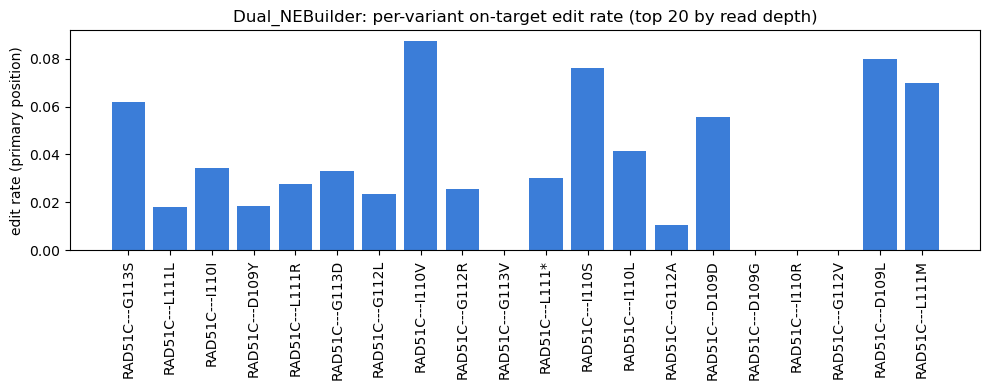

In [13]:
import matplotlib.pyplot as plt

top = tbl.head(20)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(top["Outcome"], top["edit_rate"], color="#3b7dd8")
ax.set_ylabel("edit rate (primary position)")
ax.set_title("%s: per-variant on-target edit rate (top 20 by read depth)" % LIBTYPE)
ax.tick_params(axis="x", rotation=90)
fig.tight_layout()
plt.show()